# Peak shape and microstructure

A peak's width comes from the instrument and from the specimen's small crystallites and microstrain.
To measure the specimen you have to know the instrument first.
We calibrate a synthetic instrument on a standard, save it, and load it again to measure the crystallite size and microstrain of a synthetic sample.
Both patterns are synthetic, so we know the answers and can grade each fit.
By the end you can calibrate an instrument, carry it to a sample, and read the sample's size and strain.

*Written by Claude Code, Anthropic's coding agent, for the rietx project.*

**You need** rietx 1.10 or later, which the next cell installs.
Notebook 02 introduces plans and the parameter table.

**The data** is made in the notebook: LaB₆ as the standard and CeO₂ as the sample, each computed with [`predict`](https://rietx.org/docs/stable/reference/refinement.html#entry-points) and given Poisson noise.

**Runtime** is under 30 seconds on a laptop.

In [ ]:
%pip install rietx

## How the widths combine

Each peak has a Gaussian part and a Lorentzian part, and each part has an instrument term and a specimen term.
Gaussian variances add, and Lorentzian FWHMs add.
The [specimen terms](https://rietx.org/docs/stable/reference/data.html#broadening) are each phase's `gauss_size`, `lor_size`, `gauss_strain` and `lor_strain`.
Over angle, each one follows an instrument term or a sum of two, so a fit to one pattern cannot tell them apart.
The instrument is therefore measured on its own, on a standard with no size or strain broadening.
[The instrument ⊕ sample width split](https://rietx.org/docs/stable/theory/profiles.html#the-instrument-sample-width-split) gives the equations.

## Two synthetic patterns

The standard is LaB₆.
Write its structure to a CIF and read it back.

In [1]:
import tempfile
from pathlib import Path

import numpy as np

import rietx as rx
from rietx.model.profiles.caglioti import (
    size_coefficient_for_size,
    strain_coefficient_for_microstrain,
)

work = Path(tempfile.mkdtemp())
lab6_cif = work / "LaB6.cif"
lab6_cif.write_text(
    "data_LaB6\n_space_group_name_H-M_alt 'P m -3 m'\n"
    "_cell_length_a 4.15689\n_cell_length_b 4.15689\n_cell_length_c 4.15689\n"
    "_cell_angle_alpha 90\n_cell_angle_beta 90\n_cell_angle_gamma 90\n"
    "loop_\n_atom_site_label\n_atom_site_type_symbol\n_atom_site_fract_x\n"
    "_atom_site_fract_y\n_atom_site_fract_z\n_atom_site_B_iso_or_equiv\n"
    "La1 La 0 0 0 0.25\n"
    "B1  B  0.1996 0.5 0.5 0.35\n",
    encoding="utf-8",
)
lab6 = rx.Structure.from_cif(lab6_cif)

The sample is CeO₂.

In [2]:
ceo2_cif = work / "CeO2.cif"
ceo2_cif.write_text(
    "data_CeO2\n_space_group_name_H-M_alt 'F m -3 m'\n"
    "_cell_length_a 5.411\n_cell_length_b 5.411\n_cell_length_c 5.411\n"
    "_cell_angle_alpha 90\n_cell_angle_beta 90\n_cell_angle_gamma 90\n"
    "loop_\n_atom_site_label\n_atom_site_type_symbol\n_atom_site_fract_x\n"
    "_atom_site_fract_y\n_atom_site_fract_z\n_atom_site_B_iso_or_equiv\n"
    "Ce1 Ce 0 0 0 0.3\n"
    "O1  O  0.25 0.25 0.25 0.6\n",
    encoding="utf-8",
)
ceo2 = rx.Structure.from_cif(ceo2_cif)

Next, the instrument both patterns are measured on.
Its five [width terms](https://rietx.org/docs/stable/reference/instrument.html#peak-width) and its zero shift are what the calibration should recover.

In [3]:
instrument = rx.Instrument.bragg_brentano(radiation="CuKa")
instrument.profile.u.value = 0.004
instrument.profile.v.value = -0.003
instrument.profile.w.value = 0.003
instrument.profile.x.value = 0.015
instrument.profile.y.value = 0.02
instrument.zero_shift.value = 0.02
instrument.background = rx.BackgroundChebyshev.with_terms(1)
instrument.background.coefficients[0].value = 150.0
instrument.profile

ProfileTCHZ
  shape: 'tchz_pv'
  u:     0.004 deg² 2θ
  v:     -0.003 deg² 2θ
  w:     0.003 deg² 2θ
  x:     0.015 deg 2θ
  y:     0.02 deg 2θ

Measure the standard.
`predict` computes its pattern on this instrument, and Poisson counts are drawn from it.
The phase scale puts the strongest peak near 30 000 counts.
The fits below start from `lab6` itself, at a scale of 1.

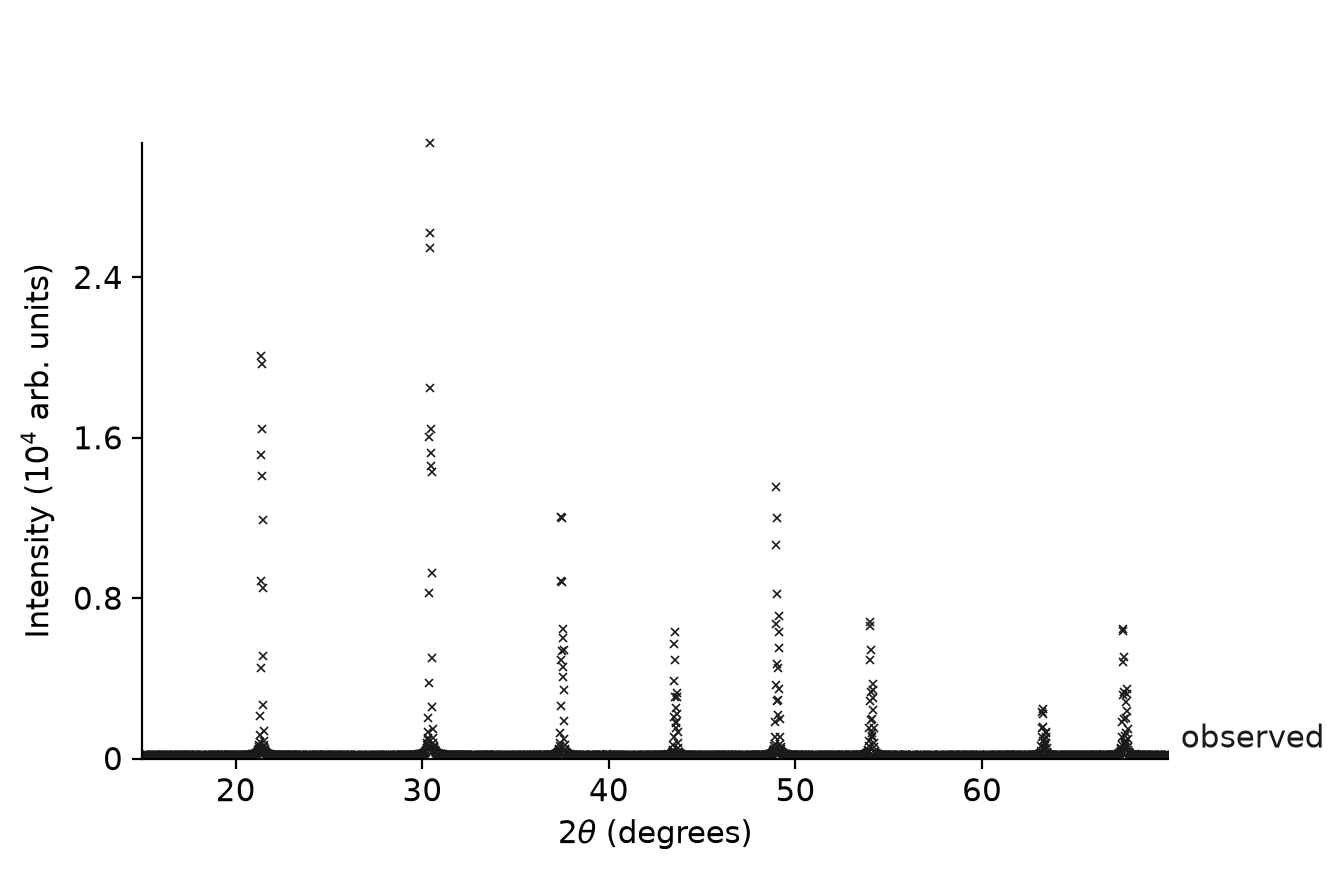

In [4]:
two_theta = np.arange(15, 130, 0.015)
rng = np.random.default_rng(0)

standard = lab6.model_copy(deep=True)
standard.phases[0].scale.value = 0.006
y = rx.Refinement(standard, instrument).predict(two_theta)
standard_data = rx.PatternData(
    two_theta=two_theta,
    intensity=rng.poisson(y).astype(float),
)
standard_data.plot(two_theta_range=(15, 70))

Measure the sample the same way, with a crystallite size and a microstrain added.
Both go into the Lorentzian terms, so the sample's Gaussian terms are truly zero.
[`size_coefficient_for_size`](https://rietx.org/docs/stable/theory/microstructure.html#reading-a-width-as-a-size) converts a size to the `lor_size` coefficient at a given wavelength.
rietx reads a size back at the source's longest emission line, so the conversion uses that line too.

In [5]:
TRUE_SIZE = 300.0  # Å, coherent domain size
TRUE_STRAIN = 1.0e-3  # Δd/d
wavelength = max(line.wavelength.value for line in instrument.source.lines)

sample_truth = ceo2.model_copy(deep=True)
phase = sample_truth.phases[0]
phase.scale.value = 0.0016
phase.lor_size.value = size_coefficient_for_size(TRUE_SIZE, wavelength)
phase.lor_strain.value = strain_coefficient_for_microstrain(TRUE_STRAIN)
y = rx.Refinement(sample_truth, instrument).predict(two_theta)
sample_data = rx.PatternData(
    two_theta=two_theta,
    intensity=rng.poisson(y).astype(float),
)

## Calibrate the instrument on the standard

Start from a default copper instrument, as you would with a real diffractometer, and give it a four-term background.
The standard's cell is known.
On a real standard it comes from the certificate, and here we set it.
[Hold](https://rietx.org/docs/stable/guides/hold.html#hold-the-parameter) the cell, so that no stage of the plan refines it.
A held cell is what lets the fit separate the zero shift and the specimen displacement from the cell.
[How to calibrate an instrument on a standard and reuse it](https://rietx.org/docs/stable/guides/calibrate.html) gives this procedure as a guide.

In [6]:
start = rx.Instrument.bragg_brentano(radiation="CuKa")
start.background = rx.BackgroundChebyshev.with_terms(4)
calibration = rx.Refinement(lab6, start)
calibration.hold(["phases.0.cell.*"])

['phases.0.cell.a',
 'phases.0.cell.alpha',
 'phases.0.cell.b',
 'phases.0.cell.beta',
 'phases.0.cell.c',
 'phases.0.cell.gamma']

`hold` returns the paths it now holds.

The `lab_calibrate` plan refines the instrument's position corrections, widths and axial divergence, one group a stage.
[Plan presets](https://rietx.org/docs/stable/reference/plans.html#lab-calibrate) draws its stages.
The synthetic instrument has no axial divergence, so expect warnings about those two terms.

In [7]:
calibrated = calibration.fit(standard_data, plan="lab_calibrate")
calibrated

RefinementResult: converged (rietveld)
  stage scale_bkg: converged (2 evals, ftol=1e-06)
  stage zero_disp: converged (49 evals, ftol=1e-06)
  stage profile_w: converged (12 evals, ftol=1e-06)
  stage profile: converged (10 evals, ftol=1e-06)
  stage lines_axial: converged (3 evals, ftol=1e-06)
  stage biso: converged (4 evals, ftol=1e-06)
  stage closing: converged (3 evals, ftol=solver default), max|Δθ|/esd=0.004
  diagnostics: 5 rows, 0 errors; no deliverable given, so none is printed in full
    FLOOR_HIT at instrument.geometry.axial_sl: warning under cell, microstructure, calibration
    FLOOR_HIT at instrument.geometry.axial_hl: warning under cell, microstructure, calibration
    HIGH_CORRELATION at instrument.geometry.axial_sl, .axial_hl: warning under every purpose
    FLAT_DIRECTION at instrument.geometry.axial_sl, .axial_hl: warning under every purpose
    HIGH_CORRELATION at instrument.zero_shift, instrument.geometry.sample_displacement: warning under every purpose
    pass deliverable= to summary() for the rows that decide your purpose; every row is in result.diagnostics
  provenance: rietx 1.10.0.dev0, backend=numpy, solver=lm
  Rwp 0.0602 / Rexp 0.0593 (GoF 1.02), Rp 0.0406, χ² 1.0, DW 2.02

The diagnostics come first.

- The data cannot tell the two axial-divergence terms apart. The synthetic instrument has neither, so there is nothing to separate.
- The zero shift and the specimen displacement still move together, even with the cell held. On real data, read the displacement's esd before quoting it.

Now compare the refined terms with the instrument that made the data.

In [8]:
TRUE_INSTRUMENT = [
    "instrument.profile.u",
    "instrument.profile.v",
    "instrument.profile.w",
    "instrument.profile.x",
    "instrument.profile.y",
    "instrument.zero_shift",
    "instrument.geometry.sample_displacement",
]
[calibrated.parameter(path) for path in TRUE_INSTRUMENT]

[instrument.profile.u  0.00407(15)  vary,
 instrument.profile.v  -0.00303(19)  vary,
 instrument.profile.w  0.003005(58)  vary,
 instrument.profile.x  0.01486(32)  vary,
 instrument.profile.y  0.02004(82)  vary,
 instrument.zero_shift  0.01993(78)  vary,
 instrument.geometry.sample_displacement  -0.0001(19)  vary]

Each term lies within about one esd of the value set above, and the displacement within one esd of zero.

## Carry the instrument to the sample

[`save_instrument_profile`](https://rietx.org/docs/stable/reference/instrument-files.html#instrument-profile) writes the calibrated instrument to a JSON file.
It leaves out the background and the specimen displacement, because they belong to one measurement and not to the instrument.

In [9]:
profile_file = work / "instrument.json"
rx.save_instrument_profile(calibration.instrument, profile_file)

[`load_instrument_profile`](https://rietx.org/docs/stable/reference/instrument-files.html#instrument-profile) reads it back with every term held.

In [10]:
calibrated_instrument = rx.load_instrument_profile(profile_file)
calibrated_instrument.profile

ProfileTCHZ
  shape: 'tchz_pv'
  u:     0.00407(15) deg² 2θ
  v:     -0.00303(19) deg² 2θ
  w:     0.003005(58) deg² 2θ
  x:     0.01486(32) deg 2θ
  y:     0.02004(82) deg 2θ

No term is marked `(vary)`, so no plan will refine them.

## Measure the sample

Give the loaded instrument a background of its own and fit the sample with [`lab_sample_refine`](https://rietx.org/docs/stable/reference/plans.html#lab-sample-refine).
The plan refines the sample's four broadening terms, its cell, its specimen displacement, its scale, its background and its Biso.
The sample starts from the CIF, with no broadening, so the fit has to find it.

In [11]:
calibrated_instrument.background = rx.BackgroundChebyshev.with_terms(4)
sample = rx.Refinement(ceo2, calibrated_instrument)
result = sample.fit(sample_data, plan="lab_sample_refine")
result

RefinementResult: converged (rietveld)
  stage scale_bkg: converged (2 evals, ftol=1e-06)
  stage disp: converged (17 evals, ftol=1e-06)
  stage cell: converged (19 evals, ftol=1e-06)
  stage sample_profile: converged (7 evals, ftol=1e-06)
  stage biso: converged (4 evals, ftol=1e-06)
  stage roughness: converged (2 evals, ftol=1e-06)
  stage closing: converged (3 evals, ftol=solver default), max|Δθ|/esd=0.008
  diagnostics: 2 rows, 0 errors; no deliverable given, so none is printed in full
    FLOOR_HIT at phases.0.gauss_size: warning under microstructure, calibration
    FLOOR_HIT at phases.0.gauss_strain: warning under microstructure, calibration
    pass deliverable= to summary() for the rows that decide your purpose; every row is in result.diagnostics
  provenance: rietx 1.10.0.dev0, backend=numpy, solver=lm
  Rwp 0.0464 / Rexp 0.0464 (GoF 1.00), Rp 0.0311, χ² 1.0, DW 2.01

Both diagnostics say a Gaussian term refined to its floor of zero.
The sample was made with no Gaussian broadening, so zero is the right answer.

[`result.microstructure`](https://rietx.org/docs/stable/reference/derived.html#size-and-strain) reads the four broadening terms as sizes and strains, one block a phase.

In [12]:
result.microstructure[0]

PhaseMicrostructure: CeO2 (phase 0), scherrer_k 0.9, wavelength 1.54443 Å
  path                   value         unavailable
  phases.0.lor_size      300.2(22) Å
  phases.0.gauss_size                  at_zero
  phases.0.lor_strain    0.000999(43)
  phases.0.gauss_strain                at_zero
  size_agreement: None   strain_agreement: None
  separable: None   size_strain_collinearity: None

The Lorentzian size and strain each lie within one esd of `TRUE_SIZE` and `TRUE_STRAIN`.
The two Gaussian rows have no reading, and [`unavailable`](https://rietx.org/docs/stable/reference/derived.html#esds-and-absent-readings) says why.
Their coefficients are at zero.

The last two lines compare readings.
[`size_agreement`](https://rietx.org/docs/stable/reference/derived.html#separating-size-from-strain) divides the Gaussian size by the Lorentzian one, and is `None` here because the Gaussian size has no reading.
`separable` says whether size and strain can be told apart over the angles fitted.
A result does not assess it.
`sample.report()` attaches the verdict when its width trend has misfit regions to read, and this fit leaves none.
[Trends across the pattern](https://rietx.org/docs/stable/concepts/report.html#trends-across-the-pattern) describes that test.

`scherrer_k` is the constant the size was read with.
It depends on crystallite shape, so the size is a coherent domain size, quoted as an order of magnitude with its K.
[Reading a width as a size](https://rietx.org/docs/stable/theory/microstructure.html#reading-a-width-as-a-size) gives the conversion.

## The same sample without calibration

Fit the sample again on a default instrument, as if we had skipped the standard.

In [13]:
skipped = rx.Instrument.bragg_brentano(radiation="CuKa")
skipped.background = rx.BackgroundChebyshev.with_terms(4)
uncalibrated = rx.Refinement(ceo2, skipped).fit(
    sample_data,
    plan="lab_sample_refine",
)
uncalibrated

RefinementResult: converged (rietveld)
  stage scale_bkg: converged (2 evals, ftol=1e-06)
  stage disp: converged (141 evals, ftol=1e-06)
  stage cell: converged (10 evals, ftol=1e-06)
  stage sample_profile: converged (9 evals, ftol=1e-06)
  stage biso: converged (5 evals, ftol=1e-06)
  stage roughness: converged (4 evals, ftol=1e-06)
  stage closing: converged (4 evals, ftol=solver default), max|Δθ|/esd=0.000
  diagnostics: none
  provenance: rietx 1.10.0.dev0, backend=numpy, solver=lm
  Rwp 0.0464 / Rexp 0.0464 (GoF 1.00), Rp 0.0311, χ² 1.0, DW 2.01

The fit converged to the same Rwp.
It raises no diagnostic, where the calibrated fit flagged its two Gaussian terms at zero.
Nothing in the agreement indices or the diagnostics says anything is wrong.
Read its microstructure.

In [14]:
uncalibrated.microstructure[0]

PhaseMicrostructure: CeO2 (phase 0), scherrer_k 0.9, wavelength 1.54443 Å
  path                   value          unavailable
  phases.0.lor_size      282.9(20) Å
  phases.0.gauss_size    6000(12000) Å
  phases.0.lor_strain    0.001134(43)
  phases.0.gauss_strain  0.00058(23)
  size_agreement: 21.3   strain_agreement: 0.51
  separable: None   size_strain_collinearity: None

The instrument's own width has gone into the sample's terms.
The Lorentzian size is now many esds below `TRUE_SIZE`, the strain several esds above `TRUE_STRAIN`, and a Gaussian size appears that the sample does not have.
`size_agreement` shows the damage without the truth.
It is about 20, so the Gaussian size is about twenty times the Lorentzian one, and the two readings do not describe one specimen.
The Gaussian size's esd is twice its value, so it is no measurement either.

## The calibrated fit

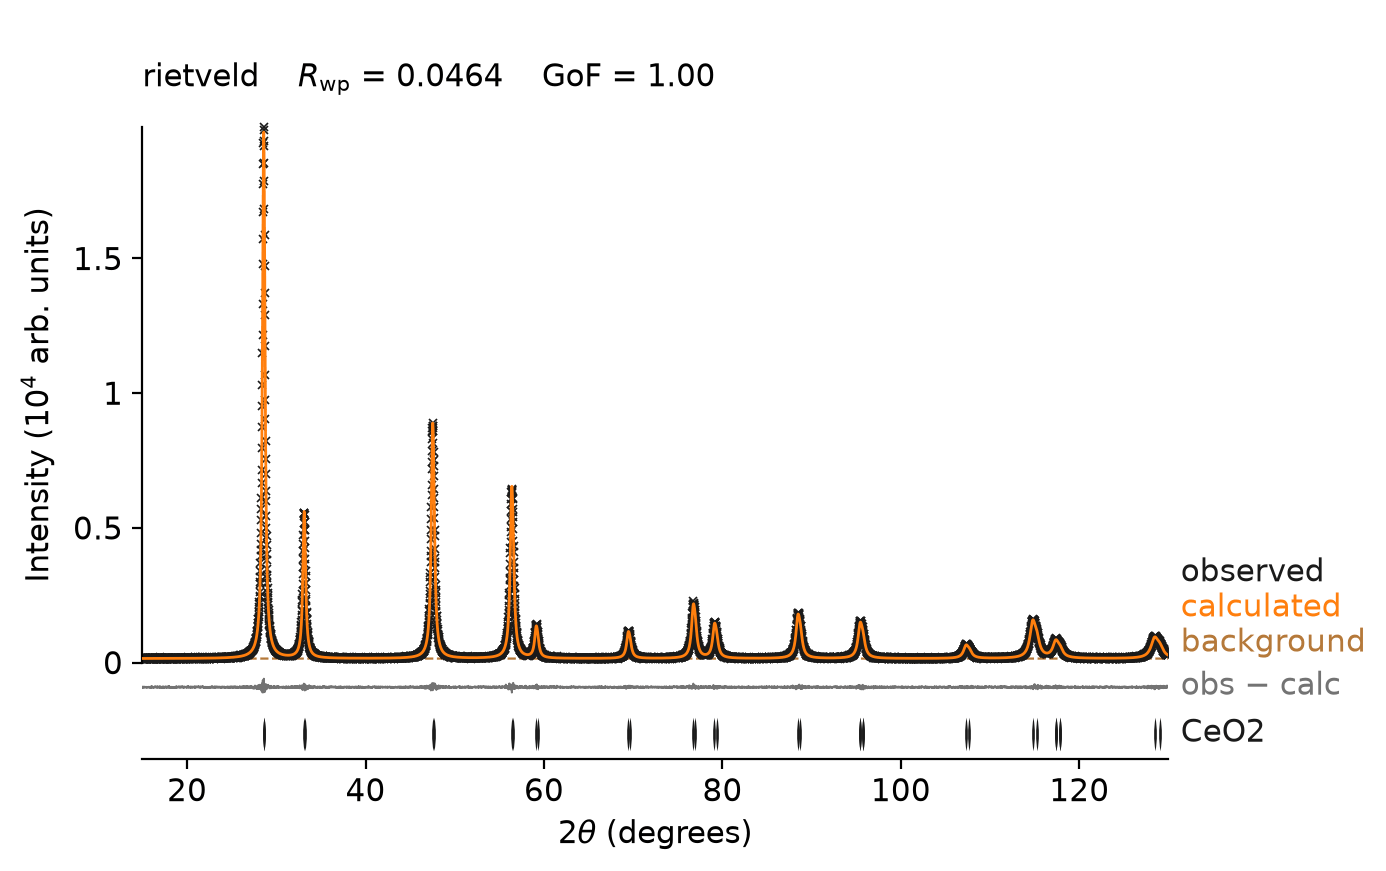

In [15]:
result.plot()

The difference curve is noise, wider only where the counts are high.
Notebook 05 chains fits along a series of patterns.